In [ ]:
# install (restart runtime if Colab asks)
!pip install -q unsloth

In [ ]:
# load + generate
from unsloth import FastLanguageModel
import torch

def load(name):
    return FastLanguageModel.from_pretrained(name, max_seq_length=512, load_in_4bit=True)

try:
    model, tok = load("unsloth/Qwen3.5-0.8B")
    print("loaded Qwen3.5-0.8B")
except Exception as e:
    print("Qwen3.5 failed:", e, "\nfalling back to Qwen3-0.6B")
    model, tok = load("unsloth/Qwen3-0.6B")

# n = sum(p.numel() for p in model.parameters())
# print(f"{n/1e9:.2f}B params")           # real count (4-bit params may show packed)
# print(f"BF16 weights: {n*2/1e9:.2f} GB, full-FT Adam: {n*16/1e9:.1f} GB")
# print(f"peak allocated: {torch.cuda.max_memory_allocated()/1e9:.2f} GB")

# FastLanguageModel.for_inference(model)

# messages = [{"role": "user", "content": "What is 12 * 7? Answer briefly."}]
# text = tok.apply_chat_template(messages, tokenize=False,
#                                add_generation_prompt=True, enable_thinking=False)
# # random but for Qwen3.5 0.8B, 2B, 4B and 9B, reasoning is disabled by default, so no need to put "enable_thinking=False"
# print(text)  # check the template by eye

# inputs = tok(text=text, return_tensors="pt").to(model.device)
# out = model.generate(**inputs, max_new_tokens=100, do_sample=False)  # greedy
# print(tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True))

# print(f"VRAM used: {torch.cuda.max_memory_allocated()/1e9:.2f} GB")

==((====))==  Unsloth 2026.10.6: Fast Qwen3_5 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for qwen3_5 won't work! Using float32.


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

loaded Qwen3.5-0.8B


----------------------------TOY RUN (200 EXAMPLES)------------------------------

In [ ]:
# datasets is its own Hugging Face library (pip name datasets), a separate package from transformers, not a module inside it.
# Unsloth installs it as a dependency, which is why the import worked in Colab.
from datasets import load_dataset

ds = load_dataset("openai/gsm8k", "main", split="train").shuffle(seed=0).select(range(200))

def to_chat(ex):
    msgs = [{"role": "user", "content": ex["question"]},
            {"role": "assistant", "content": ex["answer"]}]
    # stick to system, user and assistant: the template turns them into markers like <|im_start|>user, and the model was trained only on those.
    # Some templates raise an error on an unknown role, and others render it but the model has never seen it, so behavior is unpredictable.
    # Put your level control in the user message ([LEVEL: 3] ...) or in a system message, not in a new role.
    return {"text": tok.apply_chat_template(msgs, tokenize=False, enable_thinking=False)}
ds = ds.map(to_chat)
ds = ds.train_test_split(test_size=0.1, seed=0)   # 180 train / 20 val, so you can watch val loss
print(ds["train"][0]["text"])                     # check the template by eye

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

<|im_start|>user
Nancy has a bag containing 22 tortilla chips. She gives 7 tortilla chips to her brother and 5 tortilla chips to her sister, keeping the rest for herself. How many did Nancy keep for herself?<|im_end|>
<|im_start|>assistant
<think>

</think>

She gave away 7+5=<<7+5=12>>12 chips.
Then she kept 22-12=<<22-12=10>>10.
#### 10<|im_end|>



In [ ]:
for t in ds["train"][:10]["text"]:
    print(t)
    print("-" * 40)

<|im_start|>user
Nancy has a bag containing 22 tortilla chips. She gives 7 tortilla chips to her brother and 5 tortilla chips to her sister, keeping the rest for herself. How many did Nancy keep for herself?<|im_end|>
<|im_start|>assistant
<think>

</think>

She gave away 7+5=<<7+5=12>>12 chips.
Then she kept 22-12=<<22-12=10>>10.
#### 10<|im_end|>

----------------------------------------
<|im_start|>user
It takes Nissa 10 seconds to clip each of her cats' nails. 90 seconds to clean each of her ears, and 5 minutes to shampoo her. If the cat has four claws on each foot, how many seconds does grooming her cat take total?<|im_end|>
<|im_start|>assistant
<think>

</think>

First find the total number of claws the cat has: 4 claws/foot * 4 feet = <<4*4=16>>16 claws
Then find the total time Nissa spends cutting the claws: 16 claws * 10 seconds/claw = <<16*10=160>>160 seconds
Then find the total time she spends cleaning the cats' ears: 90 seconds/ear * 2 ears = 180 seconds
Then find how long

In [ ]:
# 1) fresh model + LoRA adapters
from unsloth import FastLanguageModel
model, tok = FastLanguageModel.from_pretrained("unsloth/Qwen3.5-0.8B", max_seq_length=512, load_in_4bit=True)
model = FastLanguageModel.get_peft_model(
    model, r=16, lora_alpha=16, lora_dropout=0, random_state=0,
    target_modules=["q_proj","k_proj","v_proj","o_proj","gate_proj","up_proj","down_proj"])
model.print_trainable_parameters()   # expect ~1% trainable

==((====))==  Unsloth 2026.10.6: Fast Qwen3_5 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for qwen3_5 won't work! Using float32.


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

Unsloth: Explicit target_modules are constrained by the finetune_(vision|language|attention|mlp) filters; adapters attach only where both select.
trainable params: 6,389,760 || all params: 859,375,680 || trainable%: 0.7435


In [ ]:
train8 = ds["train"].select(range(8))
# 2) trainer
from trl import SFTTrainer, SFTConfig
trainer = SFTTrainer(
    model=model, processing_class=tok,
    train_dataset=ds["train"], eval_dataset=ds["test"],
    args=SFTConfig(
        dataset_text_field="text", max_length=512,
        per_device_train_batch_size=8, gradient_accumulation_steps=4,   # effective batch = per_device_train_batch_size * gradient_accumulation_steps
        num_train_epochs=2, learning_rate=2e-4, warmup_ratio=0.05,
        lr_scheduler_type="cosine", logging_steps=1,
        eval_strategy="epoch", seed=0, report_to="none", output_dir="toy_run"))

Unsloth: transformers renamed `warmup_ratio` to `warmup_steps`. Forwarding your value to `warmup_steps` - update your code when convenient. If you also passed `warmup_steps` as 0.1, that is its default here and cannot be distinguished from leaving it unset, so `warmup_ratio` was used; drop `warmup_ratio` to keep it.
Unsloth: Switching to float32 training since model cannot work with float16


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/180 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


In [ ]:
print(trainer.train_dataset[0])

{'input_ids': [248045, 846, 198, 45, 6364, 682, 264, 8697, 8222, 220, 17, 17, 15944, 6045, 22858, 13, 2838, 6486, 220, 22, 15944, 6045, 22858, 310, 1024, 10326, 321, 220, 20, 15944, 6045, 22858, 310, 1024, 12553, 11, 9976, 279, 2645, 364, 11339, 13, 2500, 1599, 1467, 33102, 2426, 364, 11339, 30, 248046, 198, 248045, 74455, 198, 248068, 271, 248069, 271, 7691, 6348, 3023, 220, 22, 10, 20, 28, 2362, 22, 10, 20, 28, 16, 17, 2372, 16, 17, 22858, 13, 198, 11861, 1292, 8341, 220, 17, 17, 12, 16, 17, 28, 2362, 17, 17, 12, 16, 17, 28, 16, 15, 2372, 16, 15, 13, 198, 794, 220, 16, 15, 248046, 198], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [ ]:
# 3) loss masking: only the reply counts (the empty think block is masked too)
from unsloth.chat_templates import train_on_responses_only
trainer = train_on_responses_only(
    trainer,
    instruction_part="<|im_start|>user\n",
    response_part="<|im_start|>assistant\n<think>\n\n</think>\n\n")

Map:   0%|          | 0/180 [00:00<?, ? examples/s]

In [ ]:
print(len(trainer.train_dataset))

180


In [ ]:
# 4) verify the masking by eye BEFORE training
row = trainer.train_dataset[0]
print("FULL:  ", tok.decode(row["input_ids"]))
print("TRAINED ON:", tok.decode([t for t in row["labels"] if t != -100]))  # should be only the solution + <|im_end|>

FULL:   <|im_start|>user
Nancy has a bag containing 22 tortilla chips. She gives 7 tortilla chips to her brother and 5 tortilla chips to her sister, keeping the rest for herself. How many did Nancy keep for herself?<|im_end|>
<|im_start|>assistant
<think>

</think>

She gave away 7+5=<<7+5=12>>12 chips.
Then she kept 22-12=<<22-12=10>>10.
#### 10<|im_end|>

TRAINED ON: She gave away 7+5=<<7+5=12>>12 chips.
Then she kept 22-12=<<22-12=10>>10.
#### 10<|im_end|>


In [ ]:
# 5) train
trainer.train()

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 180 | Num Epochs = 2 | Total steps = 12
O^O/ \_/ \    Batch size per device = 8 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (8 x 4 x 1) = 32
 "-____-"     Trainable parameters = 6,389,760 of 859,375,680 (0.74% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Epoch,Training Loss,Validation Loss
1,0.708091,0.877000
2,0.736266,0.798114


TrainOutput(global_step=12, training_loss=0.9318676888942719, metrics={'train_runtime': 81.1565, 'train_samples_per_second': 4.436, 'train_steps_per_second': 0.148, 'total_flos': 253150984536576.0, 'train_loss': 0.9318676888942719, 'epoch': 2.0})

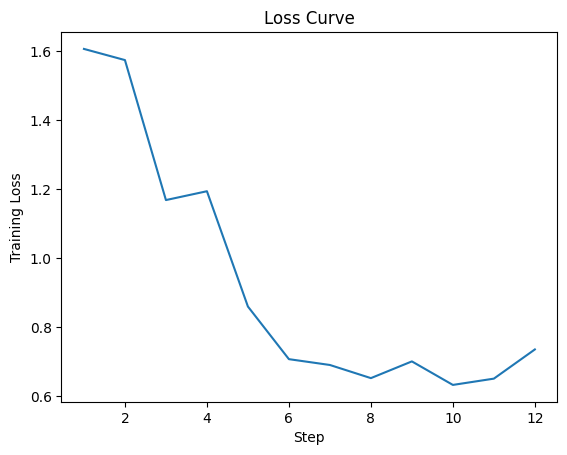

In [ ]:
import matplotlib.pyplot as plt
history = trainer.state.log_history

steps = [entry["step"] for entry in history if "loss" in entry]
losses = [entry["loss"] for entry in history if "loss" in entry]

plt.plot(steps, losses)
plt.xlabel("Step")
plt.ylabel("Training Loss")
plt.title("Loss Curve")
plt.show()

--------------------------Building the dataset----------------------------------

In [ ]:
import re
from datasets import load_dataset, Dataset, concatenate_datasets

NUM = r"\d+(?:,\d{3})*(?:\.\d+)?"
ABBR = r"(?<!Mr\.)(?<!Mrs\.)(?<!Ms\.)(?<!Dr\.)(?<!St\.)(?<!Jr\.)(?<!Sr\.)(?<!Mt\.)"
WORD_VALS = {**{w: {i} for i, w in enumerate("one two three four five six seven eight nine ten eleven twelve".split(), 1)},
             "half": {1, 2}, "halves": {1, 2}, "third": {1, 3}, "thirds": {1, 3}, "quarter": {1, 4}, "quarters": {1, 4},
             "fourth": {1, 4}, "fifth": {1, 5}, "twice": {2}, "double": {2}, "triple": {3}, "thrice": {3},
             "dozen": {12}, "percent": {100}}
PATTERNS = {
    frozenset("*+"): "equal groups plus some extras",
    frozenset("*-"): "start with a total, then remove equal groups",
    frozenset("/-"): "split something into equal shares, then take away",
    frozenset("/+"): "equal shares combined with something extra (like an average)",
    frozenset("*/"): "a part of a whole, or a rate scaled by an amount",
    frozenset("+-"): "gains and losses on a running total",
}
SINGLE = {"+": "add", "-": "subtract", "*": "multiply", "/": "divide"}

def fl(s): return abs(float(s.replace(",", "")))          # sign-insensitive numeric value

def q_last(question):                                      # last sentence with "?", safe for "Mr. Smith"
    sents = re.split(rf"{ABBR}(?<=[.?!])\s+", question.strip())
    qs = [s for s in sents if "?" in s]
    return (qs[-1] if qs else sents[-1]).strip()

def nums_in(question):                                     # quantities the question gives (digits or words)
    q = question.lower()
    vals = {fl(t) for t in re.findall(NUM, q)}
    for w in re.findall(r"[a-z]+", q):
        vals |= {float(v) for v in WORD_VALS.get(w, ())}
    return vals

def k_shown(level, p): return (level - 1) * (len(p["steps"]) - 1) // 4   # steps revealed: 0 at L1, n-1 at L5

def mask(text, question, allowed):
    t = re.sub(rf"\$?{NUM}(?:\s*[+\-*/×x÷]\s*\$?{NUM})+(?:\s*=\s*\$?{NUM})?", "___", text)  # hide the equation, keep the wording
    t = re.sub(rf"(=\s*\$?){NUM}", r"\1___", t)
    q = question.lower()
    t = re.sub(r"\b(half|twice|double|triple|thrice|third|quarter|fifth|percent)\w*",
               lambda m: m.group() if m.group(1).lower() in q else "___", t, flags=re.I)  # operation giveaways
    return re.sub(r"___(?:\s*[+\-*/×x]\s*___)+", "___", t)

def blank_result(text, v):                                 # keep the setup, hide only the step's value
    return re.sub(NUM, lambda m: "___" if fl(m.group()) == v else m.group(), text)

def op_hint(expr, text):
    e = expr.replace("×", "*").replace("÷", "/")
    ops = re.findall(r"(?<=[\d)])\s*([+\-*/])(?=\s*[\d($])", e)   # binary operators only (skips unary minus)
    if not ops: return None
    if len(set(ops)) == 1:
        return f"You will need to {SINGLE[ops[0]]} " + ("the quantities involved." if len(ops) == 1 else "several quantities.")
    pat = ("a part of a whole (a percent of an amount)" if re.search(r"%|percent", text, re.I)
           else PATTERNS.get(frozenset(ops), "a chain of several operations, built up one at a time"))
    return f"This step follows a pattern: {pat}." + (" Do the part in brackets first." if "(" in e else "")

def make(level, p):
    steps, r = p["steps"], k_shown(level, p)
    s = steps[r]                                           # frontier step: first unrevealed
    done = " ".join(x["text"] for x in steps[:r])
    allowed = nums_in(p["question"]) | {fl(x["val"]) for x in steps[:r]}
    allowed.discard(fl(s["val"]))                          # frontier result never passes through

    parts = [f"So far: {done}"] if done else []
    parts.append(f'The question asks: "{q_last(p["question"])}".')
    parts.append("Decide which quantity you can find next from what you have." if done
                 else "List the quantities you are given and decide which one is unknown.")
    if level >= 2: parts.append(f"Think about this relationship: {mask(s['text'], p['question'], allowed)}")
    if level >= 3: parts.append(op_hint(s["expr"], s["text"]) or "Take it one operation at a time.")
    if level == 4: parts.append(f"Set it up as: {s['expr']}. Work out the value yourself.")
    if level == 5: parts.append(f"Here is the step with only the result left for you: {blank_result(s['text'], fl(s['val']))}")
    return " ".join(parts)

def leaks(reply, p, level):                                # unrevealed step values + final must not appear
    r = k_shown(level, p)
    ok = nums_in(p["question"]) | {fl(x["val"]) for x in p["steps"][:r]}
    forbidden = {fl(x["val"]) for x in p["steps"][r:]} | {fl(p["final"])}
    return bool((forbidden - ok) & {fl(t) for t in re.findall(NUM, reply)})

def parse(ex):
    lines = ex["answer"].split("\n")
    final = lines[-1].replace("####", "").strip()
    if not re.fullmatch(rf"-?{NUM}", final): return None
    steps = []
    for ln in lines[:-1]:
        calcs = re.findall(r"<<([^>]*)>>", ln)
        if len(calcs) != 1 or "=" not in calcs[0]: return None
        expr, v = calcs[0].rsplit("=", 1)
        v = v.strip()
        if not re.fullmatch(rf"-?{NUM}", v): return None
        steps.append(dict(text=re.sub(r"<<[^>]*>>", "", ln).strip(), expr=expr.strip(), val=v))
    if len(steps) < 2: return None
    return dict(question=ex["question"], steps=steps, final=final)

def build_tutor(problems):
    rows, dropped = [], 0
    for pid, p in enumerate(problems):
        reps = [make(lv, p) for lv in range(1, 6)]
        if any(leaks(r, p, lv) for lv, r in enumerate(reps, 1)):   # drop whole problem, keep ladders complete
            dropped += 1; continue
        rows += [dict(pid=pid, level=lv, prompt=f"[LEVEL: {lv}]\n{p['question']}", reply=r)
                 for lv, r in enumerate(reps, 1)]
    print(f"{len(rows)//5} problems kept, {dropped} dropped for leakage")
    return Dataset.from_list(rows)

def build_replay(problems):
    return Dataset.from_list([dict(pid=-1, level=0, prompt=p["question"],
        reply="\n".join(s["text"] for s in p["steps"]) + f"\n#### {p['final']}") for p in problems])

raw = load_dataset("openai/gsm8k", "main", split="train").shuffle(seed=0)
parsed = [p for p in map(parse, raw) if p]
held, tutor, replay = parsed[:100], parsed[100:2100], parsed[2100:3600]   # disjoint by problem
print(len(parsed), "usable;", len(held), len(tutor), len(replay), "held/tutor/replay")
tutor_ds, val_ds, replay_ds = build_tutor(tutor), build_tutor(held), build_replay(replay)

5820 usable; 100 2000 1500 held/tutor/replay
1857 problems kept, 143 dropped for leakage
88 problems kept, 12 dropped for leakage


In [ ]:
from collections import Counter
print(sorted(Counter(tutor_ds["level"]).items()))   # each level should be close to 2000

[(1, 1857), (2, 1857), (3, 1857), (4, 1857), (5, 1857)]


In [ ]:
def to_text(ex):
    msgs = [{"role": "user", "content": ex["prompt"]}, {"role": "assistant", "content": ex["reply"]}]
    return {"text": tok.apply_chat_template(msgs, tokenize=False, enable_thinking=False)}

arm_a = tutor_ds.map(to_text)
arm_b = concatenate_datasets([tutor_ds, replay_ds]).shuffle(seed=0).map(to_text)
val   = val_ds.map(to_text)

# eyeball all 5 levels of a few problems, per the plan
for lv in range(1, 6):
    ex = arm_a.filter(lambda e: e["pid"] == 5 and e["level"] == lv)
    if len(ex): print(f"--- L{lv} ---\n{ex[0]['reply']}\n")

Map:   0%|          | 0/9285 [00:00<?, ? examples/s]

Map:   0%|          | 0/10785 [00:00<?, ? examples/s]

Map:   0%|          | 0/440 [00:00<?, ? examples/s]

Filter:   0%|          | 0/9285 [00:00<?, ? examples/s]

--- L1 ---
The question asks: "If it takes 2 hours to recover each animal how long did the zoo spend recovering animals?". List the quantities you are given and decide which one is unknown.



...

--- L3 ---
The question asks: "If it takes 2 hours to recover each animal how long did the zoo spend recovering animals?". List the quantities you are given and decide which one is unknown. Think about this relationship: They had to recover ___ animals You will need to add the quantities involved.



Filter:   0%|          | 0/9285 [00:00<?, ? examples/s]

--- L4 ---
The question asks: "If it takes 2 hours to recover each animal how long did the zoo spend recovering animals?". List the quantities you are given and decide which one is unknown. Think about this relationship: They had to recover ___ animals You will need to add the quantities involved. Set it up as: 3+2. Work out the value yourself.



Filter:   0%|          | 0/9285 [00:00<?, ? examples/s]

--- L5 ---
So far: They had to recover 3+2=5 animals The question asks: "If it takes 2 hours to recover each animal how long did the zoo spend recovering animals?". Decide which quantity you can find next from what you have. Think about this relationship: So it took ___ hours to recover everyone You will need to multiply the quantities involved. Here is the step with only the result left for you: So it took 5*2=___ hours to recover everyone



In [ ]:
print(len(arm_a), len(arm_b), len(val))

9285 10785 440


In [ ]:
multi = [p for p in parsed[100:2100]
         if len(set(re.findall(r"[+\-*/]", p["steps"][0]["expr"]))) > 1]
print(len(multi), "problems with a mixed-operator first step")

for p in multi[:5]:
    print("Q:", p["question"])
    print("first expr:", p["steps"][0]["expr"])
    for lv in (1, 2, 3, 4):
        print(f"--- L{lv} ---\n{make(lv, p)}\n")
    print("=" * 50)

163 problems with a mixed-operator first step
Q: If Lyn donates $240 to a private organization each year where 1/3 of it goes to the community pantry project, 1/2 goes to the local crisis fund, 1/4 of the remaining goes to livelihood project funds, and the rest is for contingency funds. How much goes to contingency fund?
first expr: 240*1/3
--- L1 ---
The question asks: "How much goes to contingency fund?". List the quantities you are given and decide which one is unknown.

--- L2 ---
So far: The community pantry project gets 240 x 1/3 = $80. The question asks: "How much goes to contingency fund?". Decide which quantity you can find next from what you have. Think about this relationship: The local crisis fund has ___.

--- L3 ---
So far: The community pantry project gets 240 x 1/3 = $80. The local crisis fund has 240 x 1/2 = $120. The question asks: "How much goes to contingency fund?". Decide which quantity you can find next from what you have. Think about this relationship: The total

--------------------EVAL HARNESS-----------------------------

In [ ]:
# The harness lives in eval_min.py (one copy; it has no parser of its own and scores this notebook's records).
# Colab: upload eval_min.py next to the notebook (or clone the repo) first.
import importlib, eval_min as em
importlib.reload(em)
em.selftest()

In [ ]:
# Eval sets. held_recs = the same 100 held-out train problems as val_ds (val_ds drops 12 whose *gold template*
# leaked; that says nothing about a model's reply, so the eval keeps all 100). solve = GSM8K test[:250].
held_recs = [em.to_rec(p) for p in held]
solve = em.build_solve_set(250)
print(len(held_recs), "held,", len(solve), "solve")

# Ceiling check: the gold tutor replies, scored by the harness. Expect exact=1.00 and zero leaks; anything
# else means the training data and the scorer disagree and the arms' numbers can't be trusted.
em.summarize([em.score(r["reply"], held_recs[r["pid"]], r["level"]) for r in val_ds], "gold replies on held (ceiling)")

--------------------ARMS: train + eval----------------------------

In [ ]:
import gc, os
from trl import SFTTrainer, SFTConfig
from unsloth.chat_templates import train_on_responses_only

MODEL = "unsloth/Qwen3.5-0.8B"
INSTR, RESP = "<|im_start|>user\n", "<|im_start|>assistant\n<think>\n\n</think>\n\n"

def free():
    gc.collect(); torch.cuda.empty_cache()

def train_arm(name, train_ds, epochs=2, lr=2e-4, seed=0, out_dir="runs"):
    """Fresh base model + LoRA, SFT on train_ds (needs a 'text' column), reply-only loss, adapter saved to out_dir/name."""
    m, t = FastLanguageModel.from_pretrained(MODEL, max_seq_length=512, load_in_4bit=True)
    m = FastLanguageModel.get_peft_model(
        m, r=16, lora_alpha=16, lora_dropout=0, random_state=seed,
        target_modules=["q_proj","k_proj","v_proj","o_proj","gate_proj","up_proj","down_proj"])
    tr = SFTTrainer(
        model=m, processing_class=t, train_dataset=train_ds, eval_dataset=val,
        args=SFTConfig(
            dataset_text_field="text", max_length=512,
            per_device_train_batch_size=8, gradient_accumulation_steps=4,
            num_train_epochs=epochs, learning_rate=lr, warmup_ratio=0.05,
            lr_scheduler_type="cosine", logging_steps=10,
            eval_strategy="epoch", seed=seed, report_to="none", output_dir=f"{out_dir}/{name}_ckpt"))
    tr = train_on_responses_only(tr, instruction_part=INSTR, response_part=RESP)
    tr.train()
    m.save_pretrained(f"{out_dir}/{name}"); t.save_pretrained(f"{out_dir}/{name}")
    return m, t, tr

def eval_arm(model, tok, name, recs=None, n_solve=None, prompted=False):
    """recs: tutor-eval records (default: all of held_recs); n_solve: use only solve[:n_solve] (for pilots)."""
    FastLanguageModel.for_inference(model)
    return em.run(model, tok, name, held_recs if recs is None else recs, solve[:n_solve], prompted=prompted, out_dir="results")

In [ ]:
# arm_c: untouched base model, rules given as a system prompt (the "just prompt it" baseline).
# Its plain-solve accuracy doubles as the base model's number for measuring what fine-tuning cost.
model, tok = FastLanguageModel.from_pretrained(MODEL, max_seq_length=512, load_in_4bit=True)
eval_arm(model, tok, "arm_c", prompted=True)
del model, tok; free()

In [ ]:
# arm_a: tutor ladders only.  (Pilots: see notes.md. Use a slice such as arm_a.select(range(320)) there.)
model, tok, tr = train_arm("arm_a_s0", arm_a)
eval_arm(model, tok, "arm_a_s0")
del model, tok, tr; free()

In [ ]:
# arm_b: tutor ladders + replay (plain solutions, no tag).
model, tok, tr = train_arm("arm_b_s0", arm_b)
eval_arm(model, tok, "arm_b_s0")
del model, tok, tr; free()

In [ ]:
em.compare(["arm_c", "arm_a_s0", "arm_b_s0"], out_dir="results")